# Homework 8.1 - Task 5

## Exact Reverse Generation and Distributional Validation

This notebook starts from the exact final Gaussian

$$
X_1\sim N(0,1)
$$

and integrates the stabilized probability-flow ODE backward to $t=0$ using the increasing reverse clock from Task 4.

The target density at $t=0$ is

$$
\frac{1}{2}N(-2,\sigma_0^2)
+
\frac{1}{2}N(2,\sigma_0^2),
$$

with

$$
\sigma_0=0.25.
$$

## Evaluation criteria

The generated distribution is compared with the target using:

- left-mode mass;
- mean;
- variance;
- fourth moment;
- mass within two component standard deviations of either target point;
- one-sample Kolmogorov-Smirnov statistic against the exact target CDF;
- one-dimensional Wasserstein distance to an independent target sample.

A target-versus-target Monte Carlo comparison is also reported to show the finite-sample scale of the Wasserstein statistic.

The same final-noise samples are reused across numerical step-size experiments.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, kstest, wasserstein_distance

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_1"

config = json.loads(
    (
        DATA_DIR
        / "task1_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

A = float(config["a"])
SIGMA0 = float(config["sigma0"])
Q = float(config["q"])

N_SAMPLES = 10000
FINAL_NOISE_SEED = 63882
TARGET_SEED = 63883
TARGET_BASELINE_SEED = 63884

In [2]:
def reverse_clock_drift(
    x,
    tau,
):
    t = 1.0 - tau
    theta = 0.5 * np.pi * t
    a_t = np.cos(theta)
    v_t = 1.0 - Q * a_t**2

    return (
        np.pi
        * np.sin(theta)
        / (2.0 * v_t)
        * (
            A
            * np.tanh(
                A
                * a_t
                * x
                / v_t
            )
            - Q
            * a_t
            * x
        )
    )


def rk4_reverse(
    initial_samples,
    n_steps,
):
    x = np.asarray(
        initial_samples,
        dtype=float,
    ).copy()

    h = 1.0 / n_steps
    tau = 0.0

    for _ in range(n_steps):
        k1 = reverse_clock_drift(
            x,
            tau,
        )

        k2 = reverse_clock_drift(
            x + 0.5 * h * k1,
            tau + 0.5 * h,
        )

        k3 = reverse_clock_drift(
            x + 0.5 * h * k2,
            tau + 0.5 * h,
        )

        k4 = reverse_clock_drift(
            x + h * k3,
            tau + h,
        )

        x = (
            x
            + h
            / 6.0
            * (
                k1
                + 2.0 * k2
                + 2.0 * k3
                + k4
            )
        )

        tau += h

    return x


def sample_target(
    n,
    seed,
):
    rng = np.random.default_rng(
        seed
    )

    labels = rng.integers(
        0,
        2,
        size=n,
    )

    means = np.where(
        labels == 0,
        -A,
        A,
    )

    return (
        means
        + SIGMA0
        * rng.normal(
            size=n
        )
    )


def target_cdf(x):
    x = np.asarray(
        x,
        dtype=float,
    )

    return (
        0.5
        * norm.cdf(
            (
                x + A
            )
            / SIGMA0
        )
        + 0.5
        * norm.cdf(
            (
                x - A
            )
            / SIGMA0
        )
    )

## 1. Analytic target moments

By symmetry,

$$
E[X]=0.
$$

The variance is

$$
E[X^2]
=
A^2+\sigma_0^2.
$$

The fourth moment is

$$
E[X^4]
=
A^4
+
6A^2\sigma_0^2
+
3\sigma_0^4.
$$

In [3]:
TARGET_MEAN = 0.0

TARGET_VARIANCE = (
    A**2
    + SIGMA0**2
)

TARGET_FOURTH_MOMENT = (
    A**4
    + 6.0
    * A**2
    * SIGMA0**2
    + 3.0
    * SIGMA0**4
)

print("Target variance:", TARGET_VARIANCE)
print("Target fourth moment:", TARGET_FOURTH_MOMENT)

Target variance: 4.0625
Target fourth moment: 17.51171875


## 2. Step-size sensitivity

The same initial standard-Gaussian noise is integrated with 250, 500, 1000, and 2000 RK4 steps.

This isolates numerical integration sensitivity from Monte Carlo variation.

In [4]:
rng = np.random.default_rng(
    FINAL_NOISE_SEED
)

initial_noise = rng.normal(
    size=N_SAMPLES
)

target_reference = sample_target(
    N_SAMPLES,
    TARGET_SEED,
)

target_baseline = sample_target(
    N_SAMPLES,
    TARGET_BASELINE_SEED,
)

step_counts = [
    250,
    500,
    1000,
    2000,
]

generated_by_steps = {}

rows = []

for n_steps in step_counts:
    generated = rk4_reverse(
        initial_noise,
        n_steps=n_steps,
    )

    generated_by_steps[
        n_steps
    ] = generated

    ks_result = kstest(
        generated,
        target_cdf,
    )

    near_modes = (
        (
            np.abs(
                generated + A
            )
            <= 2.0 * SIGMA0
        )
        | (
            np.abs(
                generated - A
            )
            <= 2.0 * SIGMA0
        )
    )

    rows.append({
        "rk4_steps": n_steps,
        "step_size": 1.0 / n_steps,
        "mean": float(
            np.mean(
                generated
            )
        ),
        "variance": float(
            np.var(
                generated,
                ddof=1,
            )
        ),
        "fourth_moment": float(
            np.mean(
                generated**4
            )
        ),
        "left_mode_mass_x_lt_0": float(
            np.mean(
                generated < 0.0
            )
        ),
        "mass_within_2sigma_of_either_target": float(
            np.mean(
                near_modes
            )
        ),
        "ks_statistic_vs_exact_target_cdf": float(
            ks_result.statistic
        ),
        "ks_pvalue": float(
            ks_result.pvalue
        ),
        "wasserstein_vs_target_reference": float(
            wasserstein_distance(
                generated,
                target_reference,
            )
        ),
    })


sensitivity = pd.DataFrame(
    rows
)

sensitivity_path = (
    DATA_DIR
    / "task5_step_size_sensitivity.csv"
)

sensitivity.to_csv(
    sensitivity_path,
    index=False,
)

print(
    sensitivity.to_string(
        index=False
    )
)

 rk4_steps  step_size      mean  variance  fourth_moment  left_mode_mass_x_lt_0  mass_within_2sigma_of_either_target  ks_statistic_vs_exact_target_cdf  ks_pvalue  wasserstein_vs_target_reference
       250     0.0040 -0.028187  4.051384      17.416719                 0.5074                               0.9522                          0.011015   0.175233                         0.011263
       500     0.0020 -0.028187  4.051384      17.416719                 0.5074                               0.9522                          0.011015   0.175233                         0.011263
      1000     0.0010 -0.028187  4.051384      17.416719                 0.5074                               0.9522                          0.011015   0.175233                         0.011263
      2000     0.0005 -0.028187  4.051384      17.416719                 0.5074                               0.9522                          0.011015   0.175233                         0.011263


## 3. Monte Carlo baseline for Wasserstein distance

In [5]:
target_baseline_w1 = float(
    wasserstein_distance(
        target_reference,
        target_baseline,
    )
)

baseline_record = {
    "target_vs_target_wasserstein": (
        target_baseline_w1
    ),
    "target_reference_samples": (
        N_SAMPLES
    ),
}

baseline_path = (
    DATA_DIR
    / "task5_target_monte_carlo_baseline.json"
)

baseline_path.write_text(
    json.dumps(
        baseline_record,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        baseline_record,
        indent=2,
    )
)

{
  "target_vs_target_wasserstein": 0.008112335185590215,
  "target_reference_samples": 10000
}


## 4. Save the main 1000-step generated sample

In [6]:
MAIN_STEPS = 1000

main_generated = (
    generated_by_steps[
        MAIN_STEPS
    ]
)

sample_table = pd.DataFrame({
    "sample_index": np.arange(
        N_SAMPLES,
        dtype=int,
    ),
    "initial_standard_gaussian": (
        initial_noise
    ),
    "generated_x_t0": (
        main_generated
    ),
    "nearest_mode": np.where(
        main_generated < 0.0,
        "left",
        "right",
    ),
})

sample_path = (
    DATA_DIR
    / "task5_exact_generated_samples.csv"
)

sample_table.to_csv(
    sample_path,
    index=False,
)

print("Saved:", sample_path.resolve())

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\data\hw8_1\task5_exact_generated_samples.csv


## 5. Histogram and exact target density

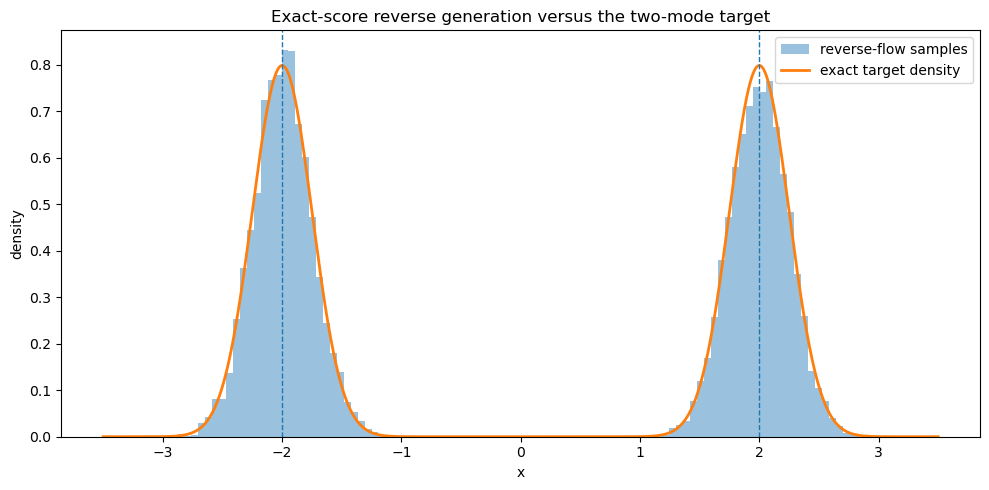

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task5_exact_generation_histogram.png


In [7]:
def target_density(x):
    return (
        0.5
        * norm.pdf(
            x,
            loc=-A,
            scale=SIGMA0,
        )
        + 0.5
        * norm.pdf(
            x,
            loc=A,
            scale=SIGMA0,
        )
    )


x_plot = np.linspace(
    -3.5,
    3.5,
    2000,
)

plt.figure(
    figsize=(10, 5)
)

plt.hist(
    main_generated,
    bins=100,
    density=True,
    alpha=0.45,
    label="reverse-flow samples",
)

plt.plot(
    x_plot,
    target_density(
        x_plot
    ),
    linewidth=2.0,
    label="exact target density",
)

plt.axvline(
    -A,
    linestyle="--",
    linewidth=1.0,
)

plt.axvline(
    A,
    linestyle="--",
    linewidth=1.0,
)

plt.xlabel("x")
plt.ylabel("density")
plt.title(
    "Exact-score reverse generation versus the two-mode target"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task5_exact_generation_histogram.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

## 6. Example reverse trajectories

A fixed set of initial-noise values is propagated through the reverse flow.

The purpose is illustrative only. Distributional validation comes from the full 10000-sample experiment above.

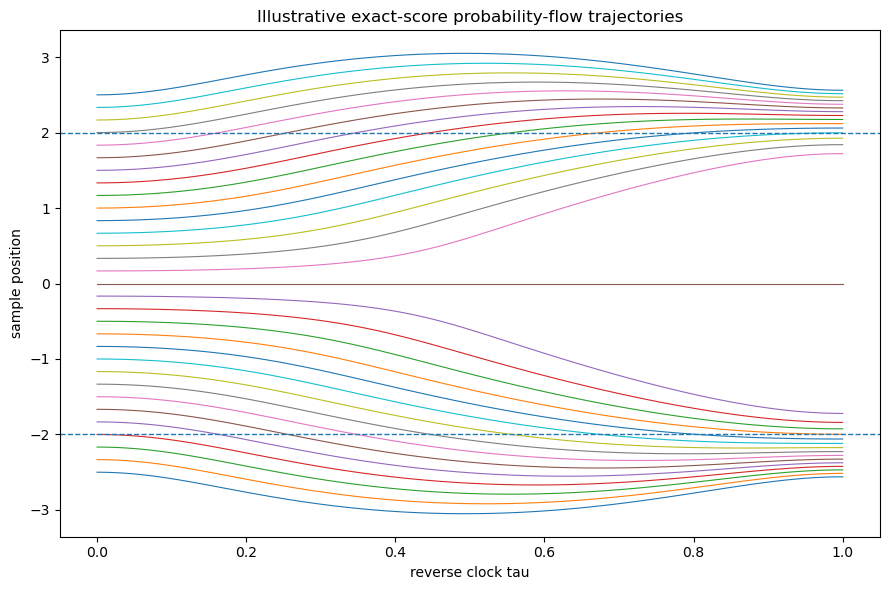

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task5_reverse_flow_trajectories.png


In [8]:
def rk4_reverse_snapshots(
    initial_samples,
    n_steps,
    snapshot_count=101,
):
    x = np.asarray(
        initial_samples,
        dtype=float,
    ).copy()

    h = 1.0 / n_steps
    tau = 0.0

    snapshot_indices = np.linspace(
        0,
        n_steps,
        snapshot_count,
        dtype=int,
    )

    snapshot_set = set(
        snapshot_indices.tolist()
    )

    tau_history = []
    x_history = []

    if 0 in snapshot_set:
        tau_history.append(
            tau
        )
        x_history.append(
            x.copy()
        )

    for step in range(
        1,
        n_steps + 1,
    ):
        k1 = reverse_clock_drift(
            x,
            tau,
        )

        k2 = reverse_clock_drift(
            x + 0.5 * h * k1,
            tau + 0.5 * h,
        )

        k3 = reverse_clock_drift(
            x + 0.5 * h * k2,
            tau + 0.5 * h,
        )

        k4 = reverse_clock_drift(
            x + h * k3,
            tau + h,
        )

        x = (
            x
            + h
            / 6.0
            * (
                k1
                + 2.0 * k2
                + 2.0 * k3
                + k4
            )
        )

        tau += h

        if step in snapshot_set:
            tau_history.append(
                tau
            )
            x_history.append(
                x.copy()
            )

    return (
        np.asarray(
            tau_history
        ),
        np.asarray(
            x_history
        ),
    )


illustrative_initial = np.linspace(
    -2.5,
    2.5,
    31,
)

tau_history, x_history = (
    rk4_reverse_snapshots(
        illustrative_initial,
        n_steps=1000,
        snapshot_count=101,
    )
)

plt.figure(
    figsize=(9, 6)
)

for j in range(
    x_history.shape[1]
):
    plt.plot(
        tau_history,
        x_history[:, j],
        linewidth=0.8,
    )

plt.axhline(
    -A,
    linestyle="--",
    linewidth=1.0,
)

plt.axhline(
    A,
    linestyle="--",
    linewidth=1.0,
)

plt.xlabel("reverse clock tau")
plt.ylabel("sample position")
plt.title(
    "Illustrative exact-score probability-flow trajectories"
)
plt.tight_layout()

path = (
    RESULT_DIR
    / "task5_reverse_flow_trajectories.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# Task 5 Conclusion

Exact-score reverse generation is evaluated against the full target distribution, not only by visual mode balance.

The step-size table reports whether the numerical result is stable as the RK4 discretization is refined.

Task 6 varies the target separation relative to the component width and distinguishes visible bimodality from latent-label distinguishability.